# Diabetes questionnaire data: a leakage-aware classification study

An educational portfolio project on the UCI *Early Stage Diabetes Risk Prediction* questionnaire dataset (ID 529): 520 rows, 16 questionnaire features and a Positive/Negative label. The aim is not a high score. It is a **careful, honest evaluation** of a small dataset that contains many identical rows.

**Sections**

1. Dataset and provenance
2. Data validation and cleaning
3. Duplicate audit and the two analyses (primary and sensitivity)
4. Grouped train/test split and cross-validation folds
5. Exploratory analysis (training rows only)
6. SQL on the training rows
7. Models, cross-validation and model selection
8. One final test evaluation
9. Primary vs sensitivity
10. Optional neural network (secondary)
11. Limitations and responsible use
12. How to reproduce

**Ground rules this project follows**

- The test set is frozen and used **once**, after every modelling choice is fixed. This notebook never reads the test rows. Section 8 only displays results that `src/s09_test_eval.py` saved.
- All preprocessing is fitted on training data only, inside scikit-learn pipelines.
- Identical questionnaire rows stay together on one side of every split ("grouped" splitting), so a model is never scored on a row it effectively saw during training.

> **Educational use only.** This is a learning project on a small questionnaire dataset. It is not a medical device and does not provide a diagnosis or medical advice. Its outputs should not be used to make healthcare decisions. Please consult a qualified healthcare professional if you have concerns about diabetes.

## Key results

Details, tables and caveats follow in the sections below.

- **The data are smaller than they look.** There are 520 rows but only 251 distinct questionnaire profiles; 269 rows are exact copies of another row. Evaluation is therefore grouped by profile, and every result is reported twice: on all 520 records (*primary*) and on the 251 unique profiles (*sensitivity*).
- **Cross-validation** (training rows only, 15 grouped folds): ROC-AUC 0.949 to 0.984 for the four models in the primary analysis and 0.951 to 0.981 in the sensitivity analysis. The majority-class baseline is exactly 0.5.
- **One test evaluation**, after the model choice was frozen: test ROC-AUC 0.929 to 0.955 (primary; 104 test rows from 49 profile groups) and 0.888 to 0.937 (sensitivity; 49 test rows). The 95% intervals are wide (0.822 to 0.997 for the chosen model in the primary analysis), so the results do not show that any one of the four models is better than another.
- **The selection rule, declared before any result existed, chose the RBF SVM** in both analyses. A small neural network (secondary experiment) scores similarly and took no part in selection.
- **Strongest patterns in the training rows:** polyuria and polydipsia (answered Yes by 72 to 79% of Positive rows and 4 to 5% of Negative rows) and gender (about 89% of the female rows are Positive, against about 46% of the male rows).
- **What this does not show:** anything about people in general, or about clinical usefulness. It is one hospital's questionnaire sample, and UCI does not document how the label was determined.

In [1]:
import hashlib
import json
import sqlite3
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import mlcommon as mc   # training-side helpers; they never read the test rows
import prep             # shared constants: column names and recoding maps

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 400)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df",
                     "axes.titleweight": "bold", "axes.titlesize": 10})
CLASS_COLOR = {"Positive": "#2a78d6", "Negative": "#eb6834"}


def load_json(name):
    return json.loads((ROOT / "reports" / name).read_text())


sel = load_json("model_selection.json")
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
frame = mc.load_training()      # also verifies the SHA-256 of the training file and the fold file
print(f"training rows: {len(frame)} | distinct questionnaire profiles: {frame['profile_id'].nunique()}")

python 3.12.16 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1
training rows: 416 | distinct questionnaire profiles: 202


## 1. Dataset and provenance

UCI states that the data were collected with direct questionnaires from patients of Sylhet Diabetes Hospital in Sylhet, Bangladesh, and approved by a doctor. This is **questionnaire data**: it is not hospital electronic health records, laboratory measurements or a clinical diagnostic dataset. The UCI page does not state how the Positive/Negative label was determined, how patients were selected, or the exact wording of each question.

In [2]:
facts = [
    ("Dataset", "Early Stage Diabetes Risk Prediction (UCI Machine Learning Repository, ID 529)"),
    ("Licence and DOI", "CC BY 4.0; doi:10.24432/C5VG8H"),
    ("Size", "520 rows x 17 columns (16 questionnaire features + class)"),
    ("Features", "age (years); gender; 14 yes/no answers: polyuria, polydipsia, sudden weight loss, weakness, polyphagia, "
                 "genital thrush, visual blurring, itching, irritability, delayed healing, partial paresis, muscle stiffness, "
                 "alopecia, obesity"),
    ("Target", "class: Positive or Negative, as recorded in the dataset"),
    ("Identifiers", "none: no patient ID, visit date or record ID"),
    ("Collection (per UCI)", "direct questionnaires given to patients of Sylhet Diabetes Hospital (Sylhet, Bangladesh), approved by a doctor"),
    ("Not stated by UCI", "how the label was determined; how patients were selected; the exact wording of the questions"),
    ("File integrity", "the downloaded archive and CSV are SHA-256 pinned in docs/DATA_SOURCE.md"),
]
pd.DataFrame(facts, columns=["item", "value"])

,item,value
0,Dataset,"Early Stage Diabetes Risk Prediction (UCI Machine Learning Repository, ID 529)"
1,Licence and DOI,CC BY 4.0; doi:10.24432/C5VG8H
2,Size,520 rows x 17 columns (16 questionnaire features + class)
3,Features,"age (years); gender; 14 yes/no answers: polyuria, polydipsia, sudden weight loss, weakness, polyphagia, genital thrush, visual blurring, itching, irritability, delayed healing, partial paresis, muscle stiffness, alopecia, obesity"
4,Target,"class: Positive or Negative, as recorded in the dataset"
5,Identifiers,"none: no patient ID, visit date or record ID"
6,Collection (per UCI),"direct questionnaires given to patients of Sylhet Diabetes Hospital (Sylhet, Bangladesh), approved by a doctor"
7,Not stated by UCI,how the label was determined; how patients were selected; the exact wording of the questions
8,File integrity,the downloaded archive and CSV are SHA-256 pinned in docs/DATA_SOURCE.md


## 2. Data validation and cleaning

Before any analysis the original file was checked against the UCI documentation (`src/s01_validate_raw.py`). The results below are read from the saved validation report. Every check passed except one **informational** mismatch: ages run from 16 to 90, while UCI documents 20 to 65. Those rows are reported and kept.

Cleaning is **deterministic recoding only**, with no learned parameters, so it is safe to apply before the split: Yes/No become 1/0, Male becomes 1, Positive becomes 1, and column names become snake_case. The recoding raises an error on any unexpected value instead of guessing. No rows are removed.

In [3]:
val = load_json("01_data_validation.json")
checks = pd.DataFrame([{"check": k.replace("_", " "),
                        "result": "pass" if v["ok"] else ("informational mismatch (rows kept)" if "informational" in k else "FAIL")}
                       for k, v in val["checks"].items()])
print(f"Observed shape: {val['shape']['rows']} rows x {val['shape']['columns']} columns | hard failures: {len(val['hard_failures'])}")
age = val["age_summary"]
print(f"Age: min {age['min']}, max {age['max']}, mean {age['mean']}, median {age['median']}; "
      f"{age['rows_outside_documented_20_65']} rows are outside the documented range 20-65 (kept).")
checks

Observed shape: 520 rows x 17 columns | hard failures: 0
Age: min 16, max 90, mean 48.03, median 47.5; 52 rows are outside the documented range 20-65 (kept).


,check,result
0,sha256 matches download record,pass
1,utf8 decodes,pass
2,no byte order mark,pass
3,line endings,pass
4,no non ascii characters,pass
5,every line has same field count,pass
6,rows match documentation,pass
7,columns match documentation,pass
8,pandas rows equal csv lines minus header,pass
9,header exact match expected,pass


In [4]:
recode_maps = pd.DataFrame({"raw column": list(prep.RAW_TO_CLEAN), "clean name": list(prep.RAW_TO_CLEAN.values())})
print("Value maps:", {**prep.YES_NO, **prep.GENDER, **prep.LABEL})
recode_maps

Value maps: {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0, 'Positive': 1, 'Negative': 0}


,raw column,clean name
0,Age,age
1,Gender,gender_male
2,Polyuria,polyuria
3,Polydipsia,polydipsia
4,sudden weight loss,sudden_weight_loss
5,weakness,weakness
6,Polyphagia,polyphagia
7,Genital thrush,genital_thrush
8,visual blurring,visual_blurring
9,Itching,itching


## 3. Duplicate audit and the two analyses

Many rows are **identical** in all 17 columns. The file has no patient identifier, so an identical row could be the same person entered more than once, a copy made while compiling the data, or different people who gave the same answers. Nothing in the data can tell which, so identical rows are reported as *identical questionnaire records* and never as repeated patients.

Because that cannot be settled, the project reports **two analyses side by side**:

- **Primary analysis: all 520 records.** Nothing is removed automatically, and no percentage threshold triggers removal.
- **Sensitivity analysis: the 251 unique questionnaire profiles**, one record per distinct set of answers.

Both use the same frozen split and folds, assigned per profile (section 4). No profile has conflicting labels, so the 251 unique records and the 251 unique profiles are the same set.

,measure,value
0,Total rows,520
1,Unique questionnaire records,251
2,Redundant copies (rows minus unique records),269 (51.73%)
3,Duplicate groups (a record appearing 2+ times),107
4,Rows inside a duplicate group,376 (72.31%)
5,Largest group of identical rows,16
6,"Conflicting profiles (same answers, different label)",0


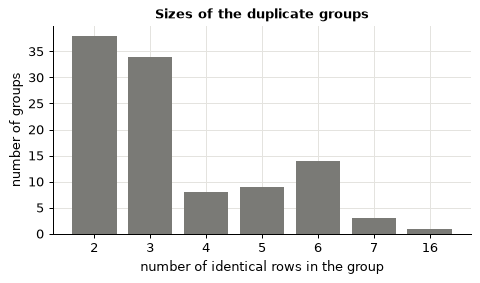

,analysis,rows,positive,negative,pct_positive
0,primary (all rows),520,320,200,61.54
1,sensitivity (unique profiles),251,173,78,68.92


In [5]:
dup = load_json("02_duplicate_audit.json")
e = dup["exact_duplicates"]
summary = pd.DataFrame([
    ("Total rows", e["total_rows"]),
    ("Unique questionnaire records", e["unique_records"]),
    ("Redundant copies (rows minus unique records)", f"{e['redundant_copies']} ({e['pct_redundant_copies']}%)"),
    ("Duplicate groups (a record appearing 2+ times)", e["duplicate_groups"]),
    ("Rows inside a duplicate group", f"{e['rows_in_duplicate_groups']} ({e['pct_rows_in_duplicate_groups']}%)"),
    ("Largest group of identical rows", max(int(k) for k in e["group_size_distribution"])),
    ("Conflicting profiles (same answers, different label)", dup["conflicting_profiles_all_rows"]["conflicting_profiles"]),
], columns=["measure", "value"])
display(summary)

sizes = pd.Series({int(k): v for k, v in e["group_size_distribution"].items()}).sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(sizes.index.astype(str), sizes.values, color="#7a7a76")
ax.set_xlabel("number of identical rows in the group")
ax.set_ylabel("number of groups")
ax.set_title("Sizes of the duplicate groups")
plt.show()

split_view = pd.DataFrame([{"analysis": "primary (all rows)", **e["class_split_all_rows"]},
                           {"analysis": "sensitivity (unique profiles)", **e["class_split_deduplicated"]}])
split_view

## 4. Grouped train/test split and cross-validation folds

The split is made **by profile**: all rows with the same 16 answers go to the same side. That is done with scikit-learn's `StratifiedGroupKFold` (stratified by class, grouped by profile). Fold 0 of a 5-fold split (seed 42) is the frozen test set. The remaining rows are the training set, on which **15 cross-validation folds** (3 repeats × 5 folds, seeds 0, 1 and 2) were also built per profile.

`StratifiedGroupKFold` tries to keep class proportions but cannot guarantee them, so the real counts are reported rather than assumed. Every split was checked: both classes on both sides, no shared profile, every training row validated once per repeat, and no test row inside any fold.

In [6]:
spl = load_json("03_split_and_cv.json")
counts = pd.DataFrame(spl["test_split_counts"]).rename(columns={"role": "analysis"})
counts = counts[["analysis", "partition", "rows", "groups", "positive", "negative", "pct_positive"]]
display(counts)

folds = pd.DataFrame(spl["cv_folds"]).rename(columns={"role": "analysis"})
fold_summary = folds.groupby("analysis").agg(
    folds=("fold", "size"), validation_rows_min=("val_rows", "min"), validation_rows_max=("val_rows", "max"),
    validation_negatives_min=("val_negative", "min"), validation_negatives_max=("val_negative", "max"),
    shared_profiles_max=("profile_overlap", "max"))
fold_summary

,analysis,partition,rows,groups,positive,negative,pct_positive
0,primary,train,416,202,256,160,61.54
1,primary,test,104,49,64,40,61.54
2,sensitivity,train,202,202,139,63,68.81
3,sensitivity,test,49,49,34,15,69.39


,folds,validation_rows_min,validation_rows_max,validation_negatives_min,validation_negatives_max,shared_profiles_max
analysis,,,,,,
primary,15,83,84,32,32,0
sensitivity,15,40,42,12,14,0


**Why the grouping matters: a small demonstration on the training data.** With ordinary row-wise cross-validation, a validation row often has an identical twin in the training part. The cell below measures how often, and compares the cross-validated ROC-AUC under both schemes for the configurations chosen later. This is an illustration only: row-wise folds are **not** used for any selection in this project.

In [7]:
vf = mc.view_frame(frame, "primary")
X, y, g = vf[mc.FEATURES], vf["label"].to_numpy(), vf["profile_id"].to_numpy()
grouped = [(tr, va) for (_r, _k, tr, va) in mc.make_splits(vf)]
rowwise = [s for seed in (0, 1, 2) for s in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y)]


def mean_auc(est0, splits):
    return float(np.mean([mc.evaluate_estimator(clone(est0).fit(X.iloc[tr], y[tr]), X.iloc[va], y[va])[0]["roc_auc"]
                          for tr, va in splits]))


def twin_rate(splits):
    """Share of validation rows whose exact 16-answer profile also occurs in the training part."""
    return float(np.mean([np.isin(g[va], g[tr]).mean() for tr, va in splits]))


rows = []
for name in ["Logistic Regression", "RBF SVM", "Random Forest"]:
    est0 = mc.build_estimator(name, sel["views"]["primary"]["models"][name]["params"])
    rows.append({"model": name, "row-wise CV ROC-AUC": mean_auc(est0, rowwise), "grouped CV ROC-AUC": mean_auc(est0, grouped)})
leak = pd.DataFrame(rows)
leak["row-wise minus grouped"] = leak["row-wise CV ROC-AUC"] - leak["grouped CV ROC-AUC"]
print(f"Validation rows with an identical-profile row in the training part: "
      f"row-wise folds {twin_rate(rowwise):.0%}, grouped folds {twin_rate(grouped):.0%}.")
leak

Validation rows with an identical-profile row in the training part: row-wise folds 68%, grouped folds 0%.


,model,row-wise CV ROC-AUC,grouped CV ROC-AUC,row-wise minus grouped
0,Logistic Regression,0.974,0.963,0.011
1,RBF SVM,0.993,0.978,0.015
2,Random Forest,0.995,0.984,0.011


Row-wise folds give a higher ROC-AUC for all three models here, by roughly 0.01 to 0.015. The gap is modest because the scores are already close to 1, but it always favours the leaky scheme, which is consistent with identical rows helping the model. Grouped folds remove that source by construction, so the scores in the rest of this notebook cannot be helped by it.

## 5. Exploratory analysis (training rows only)

Every plot and table here uses the **training rows only**. The test rows are never looked at, so nothing seen here can leak into modelling choices. Each view is shown: *primary* (all training rows) and *sensitivity* (one row per unique profile). Results are descriptive associations within one hospital's questionnaire sample: they are not causal and not population prevalence.

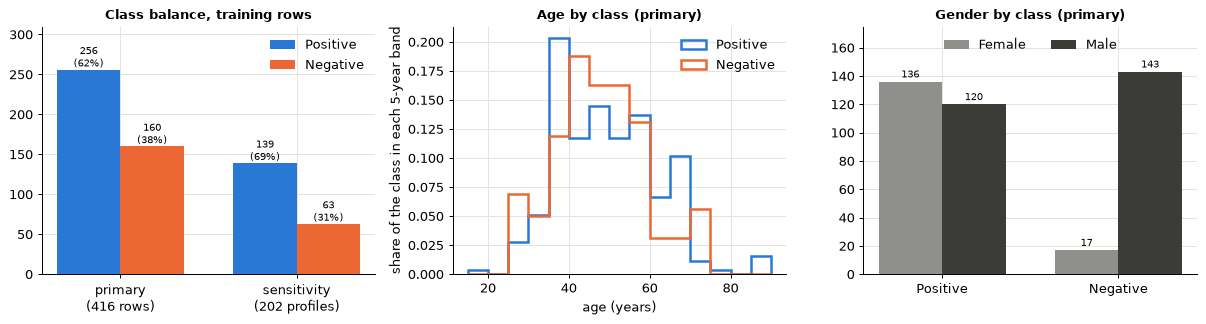

In [8]:
pri, sen = mc.view_frame(frame, "primary"), mc.view_frame(frame, "sensitivity")
cls = lambda d: d["label"].map({1: "Positive", 0: "Negative"})

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))
ax, w = axes[0], 0.36
for i, (name, d) in enumerate([("primary", pri), ("sensitivity", sen)]):
    n_pos, n_neg = int(d["label"].sum()), int(len(d) - d["label"].sum())
    ax.bar(i - w / 2, n_pos, w, color=CLASS_COLOR["Positive"], label="Positive" if i == 0 else None)
    ax.bar(i + w / 2, n_neg, w, color=CLASS_COLOR["Negative"], label="Negative" if i == 0 else None)
    ax.text(i - w / 2, n_pos + 4, f"{n_pos}\n({100 * n_pos / len(d):.0f}%)", ha="center", fontsize=8)
    ax.text(i + w / 2, n_neg + 4, f"{n_neg}\n({100 * n_neg / len(d):.0f}%)", ha="center", fontsize=8)
ax.set_xticks([0, 1], [f"primary\n({len(pri)} rows)", f"sensitivity\n({len(sen)} profiles)"])
ax.set_ylim(0, 310)
ax.set_title("Class balance, training rows")
ax.legend(frameon=False)

ax = axes[1]
bins = np.arange(15, 95, 5)
for name, c in CLASS_COLOR.items():
    ages = pri.loc[cls(pri) == name, "age"]
    ax.hist(ages, bins=bins, histtype="step", linewidth=2, color=c, weights=np.full(len(ages), 1 / len(ages)), label=name)
ax.set_xlabel("age (years)")
ax.set_ylabel("share of the class in each 5-year band")
ax.set_title("Age by class (primary)")
ax.legend(frameon=False)

ax = axes[2]
for i, name in enumerate(["Positive", "Negative"]):
    sub = pri[cls(pri) == name]
    fem, mal = int((sub["gender_male"] == 0).sum()), int((sub["gender_male"] == 1).sum())
    ax.bar(i - w / 2, fem, w, color="#8f8f8b", label="Female" if i == 0 else None)
    ax.bar(i + w / 2, mal, w, color="#3b3b38", label="Male" if i == 0 else None)
    ax.text(i - w / 2, fem + 3, str(fem), ha="center", fontsize=8)
    ax.text(i + w / 2, mal + 3, str(mal), ha="center", fontsize=8)
ax.set_xticks([0, 1], ["Positive", "Negative"])
ax.set_ylim(0, 175)
ax.set_title("Gender by class (primary)")
ax.legend(frameon=False, loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

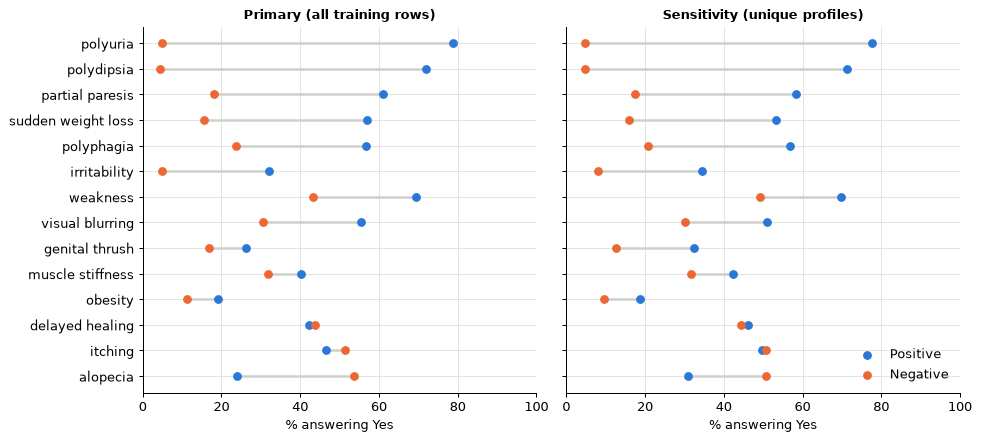

In [9]:
sym = prep.SYMPTOM_COLUMNS
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
order = None
for ax, (name, d) in zip(axes, [("Primary (all training rows)", pri), ("Sensitivity (unique profiles)", sen)]):
    prev = d.groupby("label")[sym].mean().T * 100          # column 0 = Negative, column 1 = Positive
    if order is None:
        order = (prev[1] - prev[0]).sort_values().index    # sorted by the Positive - Negative gap in the primary view
    prev = prev.loc[order]
    yy = np.arange(len(order))
    ax.hlines(yy, prev.min(axis=1), prev.max(axis=1), color="#cfcfcb", lw=2)
    ax.scatter(prev[1], yy, color=CLASS_COLOR["Positive"], label="Positive", zorder=3)
    ax.scatter(prev[0], yy, color=CLASS_COLOR["Negative"], label="Negative", zorder=3)
    ax.set_yticks(yy, [s.replace("_", " ") for s in order])
    ax.set_xlim(0, 100)
    ax.set_xlabel("% answering Yes")
    ax.set_title(name)
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
def odds_table(d):
    """Unadjusted odds ratio of each yes/no feature for the Positive class, with a 95% interval.
    A 0.5 continuity correction is added to every cell so that no count is zero."""
    out = []
    for col in ["gender_male"] + sym:
        a = ((d[col] == 1) & (d["label"] == 1)).sum() + 0.5
        b = ((d[col] == 1) & (d["label"] == 0)).sum() + 0.5
        c = ((d[col] == 0) & (d["label"] == 1)).sum() + 0.5
        dd = ((d[col] == 0) & (d["label"] == 0)).sum() + 0.5
        odds = (a * dd) / (b * c)
        se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / dd)
        out.append({"feature": col, "yes among Positive (%)": 100 * d.loc[d["label"] == 1, col].mean(),
                    "yes among Negative (%)": 100 * d.loc[d["label"] == 0, col].mean(), "odds ratio": odds,
                    "95% low": np.exp(np.log(odds) - 1.96 * se), "95% high": np.exp(np.log(odds) + 1.96 * se)})
    return pd.DataFrame(out).sort_values("odds ratio", ascending=False).reset_index(drop=True)


print("Unadjusted odds ratios, sensitivity view (one row per unique profile, so repeated rows do not inflate the certainty).")
print("For gender_male, 'yes' means male. Fifteen comparisons were made, so treat the intervals as descriptive.")
odds_table(sen)

Unadjusted odds ratios, sensitivity view (one row per unique profile, so repeated rows do not inflate the certainty).
For gender_male, 'yes' means male. Fifteen comparisons were made, so treat the intervals as descriptive.


,feature,yes among Positive (%),yes among Negative (%),odds ratio,95% low,95% high
0,polyuria,77.698,4.762,59.540,18.886,187.708
1,polydipsia,71.223,4.762,42.467,13.612,132.492
2,partial_paresis,58.273,17.460,6.360,3.092,13.081
3,sudden_weight_loss,53.237,15.873,5.795,2.765,12.149
4,irritability,34.532,7.937,5.638,2.200,14.446
5,polyphagia,56.835,20.635,4.916,2.472,9.774
6,genital_thrush,32.374,12.698,3.144,1.407,7.024
7,visual_blurring,51.079,30.159,2.382,1.272,4.459
8,weakness,69.784,49.206,2.367,1.288,4.349
9,obesity,18.705,9.524,2.065,0.827,5.155


**Reading the EDA.** In the training rows, polyuria and polydipsia show by far the biggest gaps between the classes: in the primary view polyuria is answered Yes by about 79% of Positive rows and about 5% of Negative rows. Partial paresis, sudden weight loss, polyphagia and irritability follow. Alopecia is *less* common among Positive rows, itching and delayed healing show almost no difference, and the share of Positive rows is much higher among female rows (about 89%) than among male rows (about 46%). These are patterns in one hospital's sample, not findings about people in general or about causes, and the 15 odds ratios were not corrected for multiple comparisons. Nothing here was used to choose features: every model uses all 16 questionnaire features, and the age bands used by Categorical Naive Bayes are fixed edges.

## 6. SQL on the training rows

The same questions can be answered with SQL. The queries live in `sql/train_queries.sql`. The cell below builds an **in-memory SQLite database from the training rows only** (the test rows are never loaded) and runs them. Three of them are shown with their SQL: a window function, a `CASE WHEN` grouping, and a `GROUP BY ... HAVING` duplicate check. In the SQL output, the view called `all_rows` is the primary analysis and `deduplicated` is the sensitivity analysis.

In [11]:
sql_text = (ROOT / "sql" / "train_queries.sql").read_text()
blocks, name, buf = {}, None, []
for line in sql_text.splitlines():
    if line.startswith("-- name:"):
        if name:
            blocks[name] = "\n".join(buf).strip()
        name, buf = line.split(":", 1)[1].strip(), []
    elif name:
        buf.append(line)
if name:
    blocks[name] = "\n".join(buf).strip()

con = sqlite3.connect(":memory:")
pd.read_csv(ROOT / "data" / "processed" / "train_rows.csv").to_sql("train_rows", con, index=False)
con.executescript(blocks["setup_views"])        # two views: train_dedup (one row per record) and train_both


def run(query_name, show_sql=False):
    if show_sql:
        print(blocks[query_name], "\n")
    return pd.read_sql_query(blocks[query_name], con)


print("queries available:", [n for n in blocks if n != "setup_views"])
run("class_counts", show_sql=True)

queries available: ['row_counts', 'class_counts', 'symptom_prevalence_by_class', 'gender_by_class', 'age_band_by_class', 'age_summary_by_class', 'duplicate_check_within_training', 'conflicting_profiles_within_training']
SELECT view,
       CASE label WHEN 1 THEN 'Positive' ELSE 'Negative' END AS class,
       COUNT(*) AS n,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY view), 2) AS pct_of_view
FROM train_both
GROUP BY view, label
ORDER BY view, label DESC; 



,view,class,n,pct_of_view
0,all_rows,Positive,256,61.54
1,all_rows,Negative,160,38.46
2,deduplicated,Positive,139,68.81
3,deduplicated,Negative,63,31.19


In [12]:
run("age_band_by_class", show_sql=True)

SELECT view,
       CASE WHEN age < 30 THEN '1: <30'
            WHEN age < 40 THEN '2: 30-39'
            WHEN age < 50 THEN '3: 40-49'
            WHEN age < 60 THEN '4: 50-59'
            ELSE '5: >=60' END AS age_band,
       COUNT(*) AS n,
       SUM(label) AS positive,
       COUNT(*) - SUM(label) AS negative,
       ROUND(100.0 * AVG(label), 1) AS pct_positive
FROM train_both
GROUP BY view, age_band
ORDER BY view, age_band; 



,view,age_band,n,positive,negative,pct_positive
0,all_rows,1: <30,19,8,11,42.1
1,all_rows,2: 30-39,92,65,27,70.7
2,all_rows,3: 40-49,123,67,56,54.5
3,all_rows,4: 50-59,112,65,47,58.0
4,all_rows,5: >=60,70,51,19,72.9
5,deduplicated,1: <30,8,4,4,50.0
6,deduplicated,2: 30-39,48,33,15,68.8
7,deduplicated,3: 40-49,49,33,16,67.3
8,deduplicated,4: 50-59,55,39,16,70.9
9,deduplicated,5: >=60,42,30,12,71.4


In [13]:
print("Duplicate check inside the training rows (identical in all 17 columns):")
run("duplicate_check_within_training", show_sql=True)

Duplicate check inside the training rows (identical in all 17 columns):
SELECT COUNT(*) AS duplicate_groups,
       COALESCE(SUM(n), 0) AS rows_in_duplicate_groups,
       COALESCE(SUM(n - 1), 0) AS redundant_copies
FROM (
    SELECT COUNT(*) AS n
    FROM train_rows
    GROUP BY age, gender_male, polyuria, polydipsia, sudden_weight_loss, weakness, polyphagia,
             genital_thrush, visual_blurring, itching, irritability, delayed_healing,
             partial_paresis, muscle_stiffness, alopecia, obesity, label
    HAVING COUNT(*) > 1
); 



,duplicate_groups,rows_in_duplicate_groups,redundant_copies
0,87,301,214


In [14]:
print("Positive share by gender and view:")
display(run("gender_by_class"))
print("Percentage answering Yes by class and view (first six symptoms):")
run("symptom_prevalence_by_class").iloc[:, :9]

Positive share by gender and view:


,view,gender,n,positive,negative,pct_positive
0,all_rows,Female,153,136,17,88.9
1,all_rows,Male,263,120,143,45.6
2,deduplicated,Female,71,62,9,87.3
3,deduplicated,Male,131,77,54,58.8


Percentage answering Yes by class and view (first six symptoms):


,view,class,n,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush
0,all_rows,Positive,256,78.9,71.9,57.0,69.5,56.6,26.2
1,all_rows,Negative,160,5.0,4.4,15.6,43.1,23.8,16.9
2,deduplicated,Positive,139,77.7,71.2,53.2,69.8,56.8,32.4
3,deduplicated,Negative,63,4.8,4.8,15.9,49.2,20.6,12.7


## 7. Models, cross-validation and model selection

**Models** (each is a scikit-learn pipeline whose preprocessing is fitted only on the training part of each fold):

| Model | Preprocessing | What it assumes |
|---|---|---|
| Majority-class baseline | none | always predicts the most frequent training class (so its ROC-AUC is exactly 0.5) |
| Logistic Regression (L2) | age standardised; yes/no columns unchanged | a linear effect on the log-odds |
| Categorical Naive Bayes | age in fixed bands (<30, 30-39, 40-49, 50-59, 60+); yes/no as categories | features independent given the class, which is rarely exactly true but often still ranks well |
| RBF SVM | age standardised; yes/no columns unchanged | a smooth non-linear boundary with the widest margin |
| Random Forest (300 trees) | none | many decorrelated trees vote |

Gaussian Naive Bayes is deliberately not used: it assumes continuous bell-shaped features, and 15 of the 16 features are yes/no.

**Protocol.** Hyperparameters come from small fixed grids and are scored by ROC-AUC on the 15 frozen grouped folds. There is no class weighting, resampling or threshold tuning (probability 0.5; SVM decision value 0). The selection rule was declared before any result existed and is applied separately inside each view: within a model take the best mean ROC-AUC; across models, every model within one fold-SD of the best is eligible and the **simplest eligible model** (Logistic Regression < Categorical NB < RBF SVM < Random Forest) is chosen.

In [15]:
grid_rows = []
for model, cfgs in mc.GRIDS.items():
    if not cfgs[0]:
        grid_rows.append({"model": model, "grid": "none", "configurations": 1})
        continue
    keys = list(cfgs[0])
    grid_rows.append({"model": model, "configurations": len(cfgs),
                      "grid": "; ".join(f"{k} in {list(dict.fromkeys(c[k] for c in cfgs))}" for k in keys)})
display(pd.DataFrame(grid_rows))
print(mc.build_estimator("Logistic Regression", {"C": 0.1}))

,model,grid,configurations
0,Majority-class baseline,none,1
1,Logistic Regression,"C in [0.01, 0.1, 1, 10]",4
2,Categorical NB,"alpha in [0.1, 0.5, 1.0]",3
3,RBF SVM,"C in [0.1, 1, 10]; gamma in ['scale', 0.01, 0.1]",9
4,Random Forest,"max_depth in [None, 5, 10]; min_samples_leaf in [1, 3]",6


Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('age', StandardScaler(),
                                                  ['age'])],
                                   verbose_feature_names_out=False)),
                ('clf', LogisticRegression(C=0.1, max_iter=1000))])


In [16]:
cvres = pd.read_csv(ROOT / "reports" / "model_cv_results.csv")
best = cvres[cvres["selected_within_model"]].copy()
table = best[["view", "model", "params"]].copy()
for m in mc.METRICS:
    table[mc.METRIC_TITLE[m]] = best[f"{m}_mean"].map("{:.3f}".format) + " ± " + best[f"{m}_sd"].map("{:.3f}".format)
for view in mc.VIEWS:
    print(f"\n{mc.VIEW_TITLE[view]}: cross-validation, mean ± SD over the 15 frozen folds (configuration chosen within each model)")
    display(table[table["view"] == view].drop(columns="view").reset_index(drop=True))


Primary analysis (all 520 records): cross-validation, mean ± SD over the 15 frozen folds (configuration chosen within each model)


,model,params,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Majority-class baseline,{},0.615 ± 0.002,0.615 ± 0.002,1.000 ± 0.000,0.000 ± 0.000,0.762 ± 0.001,0.500 ± 0.000
1,Logistic Regression,"{""C"": 0.1}",0.905 ± 0.038,0.940 ± 0.049,0.906 ± 0.063,0.902 ± 0.083,0.921 ± 0.032,0.963 ± 0.025
2,Categorical NB,"{""alpha"": 1.0}",0.884 ± 0.051,0.944 ± 0.051,0.866 ± 0.080,0.912 ± 0.081,0.901 ± 0.046,0.949 ± 0.031
3,RBF SVM,"{""C"": 1, ""gamma"": 0.1}",0.922 ± 0.036,0.959 ± 0.034,0.914 ± 0.060,0.935 ± 0.055,0.935 ± 0.031,0.978 ± 0.022
4,Random Forest,"{""max_depth"": 5, ""min_samples_leaf"": 1}",0.933 ± 0.035,0.964 ± 0.030,0.927 ± 0.061,0.942 ± 0.050,0.944 ± 0.031,0.984 ± 0.014



Sensitivity analysis (251 unique profiles): cross-validation, mean ± SD over the 15 frozen folds (configuration chosen within each model)


,model,params,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Majority-class baseline,{},0.688 ± 0.016,0.688 ± 0.016,1.000 ± 0.000,0.000 ± 0.000,0.815 ± 0.012,0.500 ± 0.000
1,Logistic Regression,"{""C"": 1}",0.888 ± 0.044,0.935 ± 0.045,0.902 ± 0.055,0.860 ± 0.095,0.917 ± 0.034,0.961 ± 0.026
2,Categorical NB,"{""alpha"": 0.1}",0.888 ± 0.051,0.957 ± 0.041,0.878 ± 0.063,0.911 ± 0.090,0.914 ± 0.040,0.951 ± 0.030
3,RBF SVM,"{""C"": 1, ""gamma"": ""scale""}",0.929 ± 0.039,0.964 ± 0.033,0.933 ± 0.059,0.921 ± 0.074,0.947 ± 0.030,0.981 ± 0.016
4,Random Forest,"{""max_depth"": null, ""min_samples_leaf"": 1}",0.932 ± 0.034,0.959 ± 0.029,0.942 ± 0.047,0.912 ± 0.063,0.950 ± 0.026,0.981 ± 0.018


,analysis,best model (mean CV ROC-AUC),SD of its 15 folds,threshold (best - SD),eligible,chosen
0,primary,Random Forest (0.9839),0.014,0.970,"RBF SVM, Random Forest",RBF SVM
1,sensitivity,RBF SVM (0.9810),0.016,0.965,"RBF SVM, Random Forest",RBF SVM


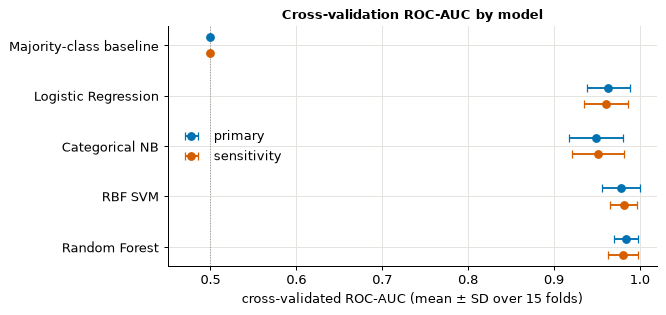

In [17]:
sel_rows = []
for view in mc.VIEWS:
    sv = sel["views"][view]
    sel_rows.append({"analysis": view, "best model (mean CV ROC-AUC)": f"{sv['best_model']} ({sv['best_mean']:.4f})",
                     "SD of its 15 folds": round(sv["sd_best"], 4), "threshold (best - SD)": round(sv["threshold"], 4),
                     "eligible": ", ".join(sv["eligible"]), "chosen": sv["chosen_model"]})
display(pd.DataFrame(sel_rows))

names = ["Majority-class baseline"] + mc.MODEL_ORDER
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, nm in enumerate(names):
    for view, off, col in (("primary", -0.16, "#0072B2"), ("sensitivity", 0.16, "#D55E00")):
        sv = sel["views"][view]
        ent = sv["baseline"] if nm == names[0] else sv["models"][nm]
        ax.errorbar(ent["roc_auc_mean"], i + off, xerr=ent["roc_auc_sd"], fmt="o", color=col, capsize=3,
                    label=view if i == 0 else None)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlim(0.45, 1.02)
ax.axvline(0.5, color="#9a9a96", lw=0.8, ls=":")
ax.set_xlabel("cross-validated ROC-AUC (mean ± SD over 15 folds)")
ax.set_title("Cross-validation ROC-AUC by model")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()
plt.show()

**Reproducing the selection inside the notebook.** The saved cross-validation results came from `src/s08_cv_select.py`. The next cell refits the four chosen configurations on the same frozen folds and checks that the mean ROC-AUC matches the saved value exactly. If anything in the data, folds or environment had changed, this would fail.

In [18]:
rows = []
for view in mc.VIEWS:
    vf = mc.view_frame(frame, view)
    Xv, yv, splits = vf[mc.FEATURES], vf["label"].to_numpy(), mc.make_splits(vf)
    for name in mc.MODEL_ORDER:
        entry = sel["views"][view]["models"][name]
        est0 = mc.build_estimator(name, entry["params"])
        aucs = [mc.evaluate_estimator(clone(est0).fit(Xv.iloc[tr], yv[tr]), Xv.iloc[va], yv[va])[0]["roc_auc"]
                for (_r, _k, tr, va) in splits]
        rows.append({"analysis": view, "model": name, "saved mean ROC-AUC": entry["roc_auc_mean"],
                     "re-run mean ROC-AUC": float(np.mean(aucs)),
                     "identical": bool(np.isclose(np.mean(aucs), entry["roc_auc_mean"], rtol=0, atol=1e-12))})
check = pd.DataFrame(rows)
assert check["identical"].all(), "re-run does not reproduce the saved cross-validation results"
check

,analysis,model,saved mean ROC-AUC,re-run mean ROC-AUC,identical
0,primary,Logistic Regression,0.963,0.963,True
1,primary,Categorical NB,0.949,0.949,True
2,primary,RBF SVM,0.978,0.978,True
3,primary,Random Forest,0.984,0.984,True
4,sensitivity,Logistic Regression,0.961,0.961,True
5,sensitivity,Categorical NB,0.951,0.951,True
6,sensitivity,RBF SVM,0.981,0.981,True
7,sensitivity,Random Forest,0.981,0.981,True


**Interpreting a model: Logistic Regression odds ratios.** The cell fits the chosen Logistic Regression configuration on the full primary **training** set and reads its coefficients as odds ratios. An odds ratio above 1 means that answering Yes (or being older, for age) goes with higher odds of the Positive label **in this sample, holding the other answers fixed**. With 16 correlated questionnaire items, a regularised model (C = 0.1) and a small sample, treat the ordering as a description of the model, not a statement about causes. Age has an odds ratio below 1 here (slightly lower odds with older age once the answers are held fixed), while the raw age-band table in section 6 shows no clear trend, so this should not be read as an effect of ageing.

,feature,odds ratio,unit
0,polyuria,4.493,Yes vs No
1,polydipsia,3.485,Yes vs No
2,irritability,1.905,Yes vs No
3,partial_paresis,1.718,Yes vs No
4,sudden_weight_loss,1.558,Yes vs No
5,genital_thrush,1.534,Yes vs No
6,polyphagia,1.517,Yes vs No
7,visual_blurring,1.358,Yes vs No
8,weakness,1.350,Yes vs No
9,obesity,1.093,Yes vs No


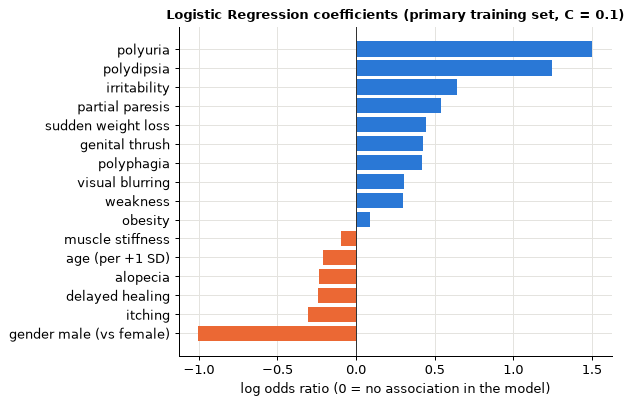

In [19]:
vf = mc.view_frame(frame, "primary")
lr = mc.build_estimator("Logistic Regression", sel["views"]["primary"]["models"]["Logistic Regression"]["params"])
lr.fit(vf[mc.FEATURES], vf["label"])
coefs = lr.named_steps["clf"].coef_[0]                     # same order as mc.FEATURES: age (standardised) first
age_sd = float(vf["age"].std(ddof=0))
odds = pd.DataFrame({"feature": mc.FEATURES, "odds ratio": np.exp(coefs)})
units = {"age": f"per +1 SD of age (SD = {age_sd:.1f} years)", "gender_male": "male vs female"}
odds["unit"] = odds["feature"].map(lambda f: units.get(f, "Yes vs No"))
odds = odds.sort_values("odds ratio", ascending=False).reset_index(drop=True)
display(odds)

fig, ax = plt.subplots(figsize=(7, 4.6))
plot = odds.iloc[::-1]
plot_labels = plot["feature"].map({"age": "age (per +1 SD)", "gender_male": "gender male (vs female)"}).fillna(plot["feature"])
ax.barh(plot_labels.str.replace("_", " "), np.log(plot["odds ratio"]),
        color=np.where(plot["odds ratio"] >= 1, CLASS_COLOR["Positive"], CLASS_COLOR["Negative"]))
ax.axvline(0, color="#333333", lw=0.8)
ax.set_xlabel("log odds ratio (0 = no association in the model)")
ax.set_title(f"Logistic Regression coefficients (primary training set, C = {lr.named_steps['clf'].C})")
plt.tight_layout()
plt.show()

**Using the saved pipeline.** The primary analysis's chosen model (an RBF SVM) was refitted on the full primary training set and saved with `joblib`. Reloading it must give identical predictions; `src/s09_test_eval.py` checked that on the test set. Below it is applied to two **synthetic example profiles** (invented, not real people) to show the intended output: the **predicted dataset class only**. Numeric probabilities are deliberately not shown, because none of these models was probability-calibrated.

**Requires a local-only file, so this part cannot be fully reproduced from the public repository.** The next cell loads `models/primary_demo_pipeline.joblib`, the research-selected RBF SVM. An RBF SVM stores its support vectors, which are copies of 127 of the 416 training rows, inside the saved file. The file therefore stays on the author's computer and is not in the public repository. From a clone the cell stops with a `FileNotFoundError`; the output shown below was produced in the author's working copy. (Re-running the rest of the notebook also needs the unpublished `data/` folder; see the README, *Reproduce the analysis*.) The Streamlit app does not use this file: it uses a separate, demo-only Logistic Regression whose file holds no training rows (see the README, *Models in this project*).

In [20]:
# LOCAL-ONLY FILE. This cell needs models/primary_demo_pipeline.joblib, the research-selected RBF SVM. The file stores
# 127 of the 416 training rows as support vectors, so it is not in the public repository. From a clone the next line
# raises FileNotFoundError and this cell cannot be reproduced; the output below was produced in the working copy.
pipe = joblib.load(ROOT / "models" / "primary_demo_pipeline.joblib")
examples = {"Synthetic profile A (age 45, male, every symptom answered No)": {"age": 45, "gender_male": 1},
            "Synthetic profile B (as A, but polyuria and polydipsia answered Yes)":
                {"age": 45, "gender_male": 1, "polyuria": 1, "polydipsia": 1}}
for title, answers in examples.items():
    row = pd.DataFrame([{**{c: 0 for c in mc.FEATURES}, **answers}])[mc.FEATURES]
    print(f"{title}: predicted dataset class = {'Positive' if int(pipe.predict(row)[0]) == 1 else 'Negative'}")
print("These inputs are invented and only show the output format. A predicted class is a model output, not a diagnosis.")

Synthetic profile A (age 45, male, every symptom answered No): predicted dataset class = Negative
Synthetic profile B (as A, but polyuria and polydipsia answered Yes): predicted dataset class = Positive
These inputs are invented and only show the output format. A predicted class is a model output, not a diagnosis.


## 8. One final test evaluation

After the selection file was frozen (its SHA-256 recorded), `src/s09_test_eval.py` refitted each model's chosen configuration on the full training set of each view and evaluated it **once** on that view's test set. No test result changed a configuration, a model choice or the selection. This notebook does not read the test rows: it only displays the saved results.

Intervals are 95% **group-bootstrap** intervals: the test profiles are resampled with replacement (1,000 times, seed 2026), because rows from the same profile receive identical predictions and are not independent. The primary test set has 104 rows but only 49 profile groups, and the sensitivity test set has 49 rows (15 Negative), so the intervals are wide.

In [21]:
tst = load_json("model_test_results.json")
recorded = (ROOT / "reports" / "model_selection.sha256").read_text().split()[0]
actual = hashlib.sha256((ROOT / "reports" / "model_selection.json").read_bytes()).hexdigest()
print("selection file: recorded hash == actual hash == the one the test evaluation used:", recorded == actual == tst["selection_sha256"])


def with_ci(entry, m):
    v, lo, hi = entry["metrics"][m], *entry["ci95"][m]
    return "undefined" if v is None else f"{v:.3f} [{lo:.3f}, {hi:.3f}]"


for view in mc.VIEWS:
    tv = tst["views"][view]
    print(f"\n{mc.VIEW_TITLE[view]}: {tv['n_test_rows']} test rows from {tv['n_test_groups']} profile groups "
          f"({tv['test_positive']} Positive, {tv['test_negative']} Negative)")
    ordered = [(mname, tv["models"][mname]) for mname in [mc.BASELINE] + mc.MODEL_ORDER]
    display(pd.DataFrame([{"model": mname, **{mc.METRIC_TITLE[m]: with_ci(e, m) for m in mc.METRICS}}
                          for mname, e in ordered]))
    display(pd.DataFrame([{"model": mname, **{k.upper(): e["confusion"][k] for k in ("tn", "fp", "fn", "tp")}}
                          for mname, e in ordered]))

selection file: recorded hash == actual hash == the one the test evaluation used: True

Primary analysis (all 520 records): 104 test rows from 49 profile groups (64 Positive, 40 Negative)


,model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Majority-class baseline,"0.615 [0.395, 0.832]","0.615 [0.395, 0.832]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.762 [0.567, 0.908]","0.500 [0.500, 0.500]"
1,Logistic Regression,"0.846 [0.705, 0.943]","0.875 [0.703, 1.000]","0.875 [0.766, 0.957]","0.800 [0.454, 1.000]","0.875 [0.758, 0.953]","0.955 [0.854, 0.995]"
2,Categorical NB,"0.856 [0.722, 0.948]","0.889 [0.721, 1.000]","0.875 [0.764, 0.957]","0.825 [0.500, 1.000]","0.882 [0.764, 0.958]","0.929 [0.792, 0.990]"
3,RBF SVM,"0.856 [0.716, 0.951]","0.877 [0.706, 1.000]","0.891 [0.786, 0.971]","0.800 [0.454, 1.000]","0.884 [0.772, 0.959]","0.944 [0.822, 0.997]"
4,Random Forest,"0.856 [0.719, 0.948]","0.866 [0.703, 0.985]","0.906 [0.804, 0.981]","0.775 [0.400, 0.976]","0.885 [0.777, 0.959]","0.930 [0.794, 0.991]"


,model,TN,FP,FN,TP
0,Majority-class baseline,0,40,0,64
1,Logistic Regression,32,8,8,56
2,Categorical NB,33,7,8,56
3,RBF SVM,32,8,7,57
4,Random Forest,31,9,6,58



Sensitivity analysis (251 unique profiles): 49 test rows from 49 profile groups (34 Positive, 15 Negative)


,model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Majority-class baseline,"0.694 [0.551, 0.816]","0.694 [0.551, 0.816]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.819 [0.711, 0.899]","0.500 [0.500, 0.500]"
1,Logistic Regression,"0.776 [0.653, 0.878]","0.871 [0.741, 0.969]","0.794 [0.656, 0.919]","0.733 [0.500, 0.938]","0.831 [0.721, 0.919]","0.906 [0.808, 0.976]"
2,Categorical NB,"0.816 [0.714, 0.918]","0.903 [0.781, 1.000]","0.824 [0.688, 0.941]","0.800 [0.583, 1.000]","0.862 [0.762, 0.938]","0.888 [0.792, 0.969]"
3,RBF SVM,"0.816 [0.714, 0.918]","0.879 [0.756, 0.971]","0.853 [0.727, 0.969]","0.733 [0.500, 0.938]","0.866 [0.769, 0.943]","0.937 [0.859, 0.991]"
4,Random Forest,"0.837 [0.735, 0.939]","0.882 [0.759, 0.972]","0.882 [0.765, 0.974]","0.733 [0.500, 0.938]","0.882 [0.794, 0.955]","0.935 [0.857, 0.988]"


,model,TN,FP,FN,TP
0,Majority-class baseline,0,15,0,34
1,Logistic Regression,11,4,7,27
2,Categorical NB,12,3,6,28
3,RBF SVM,11,4,5,29
4,Random Forest,11,4,4,30


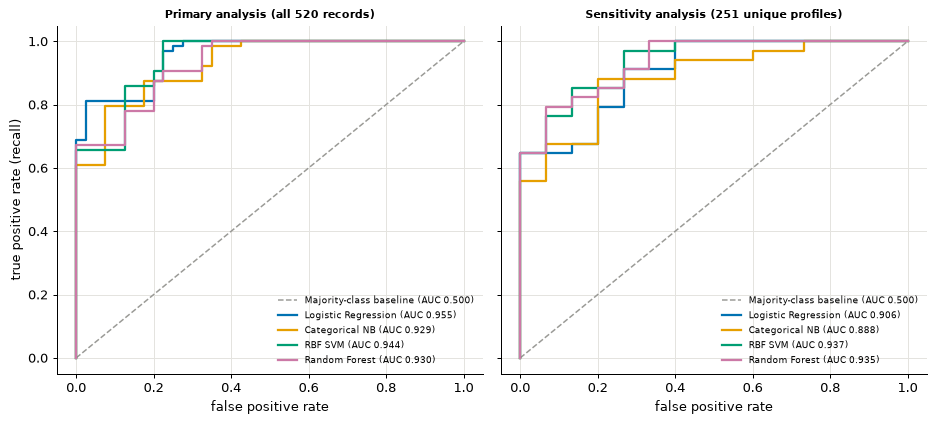

In [22]:
colors = {"Logistic Regression": "#0072B2", "Categorical NB": "#E69F00", "RBF SVM": "#009E73", "Random Forest": "#CC79A7"}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True)
for ax, view in zip(axes, mc.VIEWS):
    for mname in [mc.BASELINE] + mc.MODEL_ORDER:
        e = tst["views"][view]["models"][mname]
        auc = e["metrics"]["roc_auc"]
        if mname == "Majority-class baseline":
            ax.plot([0, 1], [0, 1], ls="--", color="#9a9a96", lw=1.2, label=f"{mname} (AUC {auc:.3f})")
        else:
            ax.plot(e["roc"]["fpr"], e["roc"]["tpr"], color=colors[mname], lw=1.8, label=f"{mname} (AUC {auc:.3f})")
    ax.set_title(mc.VIEW_TITLE[view], fontsize=9)
    ax.set_xlabel("false positive rate")
    ax.legend(loc="lower right", fontsize=7.5, frameon=False)
axes[0].set_ylabel("true positive rate (recall)")
plt.tight_layout()
plt.show()

## 9. Primary vs sensitivity

The two analyses answer slightly different questions. In the primary view every record counts, so profiles that occur many times weigh more. The sensitivity view counts each unique profile once and has a smaller, duplicate-free sample. Neither is "more correct": the project reports both.

In [23]:
four = mc.MODEL_ORDER
rows = []
for mname in ["Majority-class baseline"] + four:
    def cv_auc(view):
        sv = sel["views"][view]
        return (sv["baseline"] if mname == "Majority-class baseline" else sv["models"][mname])["roc_auc_mean"]
    tp_, ts_ = (tst["views"][v]["models"][mname]["metrics"] for v in mc.VIEWS)
    rows.append({"model": mname, "CV AUC primary": cv_auc("primary"), "CV AUC sensitivity": cv_auc("sensitivity"),
                 "test AUC primary": tp_["roc_auc"], "test AUC sensitivity": ts_["roc_auc"],
                 "test recall P / S": f"{tp_['recall']:.3f} / {ts_['recall']:.3f}",
                 "test specificity P / S": f"{tp_['specificity']:.3f} / {ts_['specificity']:.3f}"})
compare = pd.DataFrame(rows)
display(compare)

rank_cv = {v: sorted(four, key=lambda m: -sel["views"][v]["models"][m]["roc_auc_mean"]) for v in mc.VIEWS}
chosen = {v: sel["views"][v]["chosen_model"] for v in mc.VIEWS}
print("CV ranking, primary    :", " > ".join(rank_cv["primary"]))
print("CV ranking, sensitivity:", " > ".join(rank_cv["sensitivity"]))
print("Model chosen by the rule: primary =", chosen["primary"], "| sensitivity =", chosen["sensitivity"],
      "->", "same model" if chosen["primary"] == chosen["sensitivity"] else "different models")

,model,CV AUC primary,CV AUC sensitivity,test AUC primary,test AUC sensitivity,test recall P / S,test specificity P / S
0,Majority-class baseline,0.500,0.500,0.500,0.500,1.000 / 1.000,0.000 / 0.000
1,Logistic Regression,0.963,0.961,0.955,0.906,0.875 / 0.794,0.800 / 0.733
2,Categorical NB,0.949,0.951,0.929,0.888,0.875 / 0.824,0.825 / 0.800
3,RBF SVM,0.978,0.981,0.944,0.937,0.891 / 0.853,0.800 / 0.733
4,Random Forest,0.984,0.981,0.930,0.935,0.906 / 0.882,0.775 / 0.733


CV ranking, primary    : Random Forest > RBF SVM > Logistic Regression > Categorical NB
CV ranking, sensitivity: RBF SVM > Random Forest > Logistic Regression > Categorical NB
Model chosen by the rule: primary = RBF SVM | sensitivity = RBF SVM -> same model


**Takeaways.** The rule picks the same model, the RBF SVM, in both views, although the cross-validation ranking at the top (Random Forest vs RBF SVM) differs. Differences between the four fitted models are small relative to the bootstrap intervals, so the test results do not support claiming that one model is better than another. For every model in both views, the test ROC-AUC is below the cross-validation ROC-AUC. That is the direction expected when cross-validation was also used to choose the configurations, but the test set is small, so the size of each gap is itself uncertain. The majority-class baseline shows what "no information" looks like (ROC-AUC exactly 0.5, specificity 0).

## 10. Optional neural network (secondary experiment)

A small feed-forward network (16 → 16 → 8 → 1, ReLU, dropout 0.2) was trained with PyTorch as a secondary experiment, using the same frozen folds and test set. It takes no part in model selection and is not deployed. For every outer fold and seed the epoch count was chosen by early stopping on a **group-separated inner validation split**; then a **fresh network was retrained on the whole outer training fold for exactly that many epochs** and evaluated only on the untouched outer validation fold (or the test set). Seeds 0–4, CPU only, deterministic mode, with a separately seeded data-loader generator. The notebook displays the saved results; it does not retrain the network.

,analysis,CV ROC-AUC,test ROC-AUC (seed-averaged) [95%],test accuracy / recall / specificity,epochs in final fits (seeds 0-4)
0,primary,0.959 ± 0.028,"0.949 [0.833, 0.996]",0.865 / 0.906 / 0.800,"[28, 29, 66, 21, 72]"
1,sensitivity,0.961 ± 0.024,"0.927 [0.838, 0.988]",0.816 / 0.853 / 0.733,"[103, 163, 94, 87, 117]"


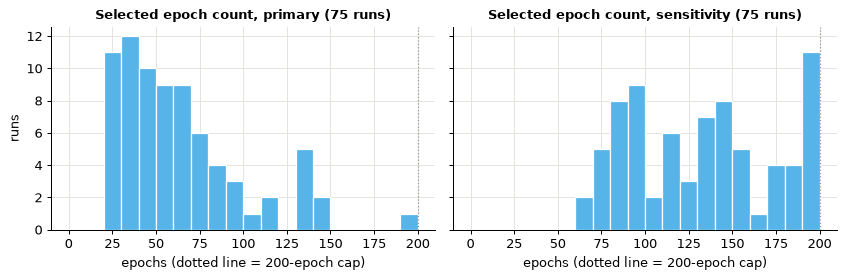

Runs where the 200-epoch cap ended training before early stopping could trigger (best epoch 181 or later): {'primary': 1, 'sensitivity': 15}


In [24]:
fnn = load_json("fnn_results.json")
fcv = pd.read_csv(ROOT / "reports" / "fnn_cv_results.csv")
rows = []
for view in mc.VIEWS:
    c, t = fnn["views"][view]["cv"], fnn["views"][view]["test"]
    sa = t["seed_averaged"]
    rows.append({"analysis": view, "CV ROC-AUC": f"{c['metrics_mean']['roc_auc']:.3f} ± {c['metrics_sd']['roc_auc']:.3f}",
                 "test ROC-AUC (seed-averaged) [95%]": f"{sa['metrics']['roc_auc']:.3f} [{sa['ci95']['roc_auc'][0]:.3f}, {sa['ci95']['roc_auc'][1]:.3f}]",
                 "test accuracy / recall / specificity": f"{sa['metrics']['accuracy']:.3f} / {sa['metrics']['recall']:.3f} / {sa['metrics']['specificity']:.3f}",
                 "epochs in final fits (seeds 0-4)": t["epochs_per_seed"]})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
for ax, view in zip(axes, mc.VIEWS):
    ax.hist(fcv.loc[fcv["view"] == view, "epochs"], bins=np.arange(0, 210, 10), color="#56B4E9", edgecolor="white")
    ax.axvline(200, color="#9a9a96", ls=":", lw=1)
    ax.set_title(f"Selected epoch count, {view} (75 runs)")
    ax.set_xlabel("epochs (dotted line = 200-epoch cap)")
axes[0].set_ylabel("runs")
plt.tight_layout()
plt.show()
capped = fcv[fcv["epochs"] >= 181].groupby("view").size().reindex(mc.VIEWS, fill_value=0)
print("Runs where the 200-epoch cap ended training before early stopping could trigger (best epoch 181 or later):", capped.to_dict())

In the sensitivity analysis, 15 of the 75 cross-validation runs reached the 200-epoch cap, so for those runs the chosen epoch count may be lower than early stopping alone would have picked. None of the five final fits (the ones scored on the test set) reached the cap. The network's cross-validation ROC-AUC (0.959 primary, 0.961 sensitivity) is close to Logistic Regression's (0.963 and 0.961).

## 11. Limitations and responsible use

- **One hospital, questionnaire data.** UCI does not state how the label was determined or how patients were selected, so these results say nothing about other hospitals or populations, and nothing about electronic health records or laboratory tests.
- **Small sample and identical rows.** There are 520 rows but only 251 unique profiles. The test sets (104 rows from 49 profiles; 49 rows with 15 Negative) are small, so intervals are wide and model differences are not resolved. A single hold-out split is one draw of which profiles land in the test set.
- **Identical rows cannot be interpreted.** Without an identifier they may be repeated entries, copies or different people with the same answers. That is why both analyses are reported.
- **What the features are.** Several items (for example polyuria and polydipsia) are classic symptoms of established diabetes, so a high score may reflect recognising symptom patterns rather than anticipating future disease. The documentation does not say when the symptoms occurred relative to the label.
- **Age.** The documented range is 20–65; 52 rows are outside it. They were kept and reported.
- **Scores and probabilities.** Predictions use a fixed threshold. No probability calibration was done, so no numeric probabilities are shown or should be read from these models.
- **Optimism.** The same folds were used to choose configurations and the model, so cross-validation scores are mildly optimistic. Bootstrap intervals describe uncertainty conditional on the fitted models and the frozen test split, not model-selection uncertainty.
- **No external test.** Nothing here was checked on data from another source.
- **Not for care decisions.** This is an educational project. High scores on this sample are not evidence of clinical usefulness.

## 12. How to reproduce

See the README for the full steps. In short: install the pinned packages (`requirements-analysis.txt`), download the UCI archive and check its SHA-256 (`docs/DATA_SOURCE.md`), run `python src/rebuild_processed_data.py` if `data/processed/` is empty, then run this notebook. The experiments themselves are scripts that verify their frozen inputs by SHA-256 before use:

| Script | What it does |
|---|---|
| `src/s08_cv_select.py` | cross-validated model selection on the training data only; writes the selection file and its hash |
| `src/s09_test_eval.py` | verifies the selection hash, then runs the single test evaluation and saves the selected RBF SVM (kept local: it stores training rows) |
| `src/s10_fnn.py` | optional neural network (needs PyTorch) |
| `src/s11_build_report.py` | builds `reports/09_model_results.md` and its figures from the saved results |
| `src/s12_demo_model.py` | fits the demo-only Logistic Regression that the Streamlit app uses, inspects what its saved file contains, and writes it only if it holds no training rows |

Software used: see the first cell's output and `requirements-analysis.txt`.